reads Kc using input(), prints the data type of the raw input and of the converted value ,amd shows a clear message (no crash) if the text is not a number or if Kc=<0; give me code for this

In [1]:
import math

raw_kc = input("Enter the equilibrium constant Kc: ")
print("Raw input type:", type(raw_kc).__name__)

try:
    Kc = float(raw_kc)
    print("Converted value:", Kc)
    print("Converted value type:", type(Kc).__name__)

    if not math.isfinite(Kc) or Kc <= 0:
        print("Invalid Kc: enter a finite number greater than 0.")
    else:
        print("Kc is valid.")

except ValueError:
    print("Invalid input: please enter a number.")

Raw input type: str
Converted value: 3.0
Converted value type: float
Kc is valid.


finds a,b,c,the discriminant and both roots;





In [2]:
import math

raw_kc = input("Enter Kc: ")
print("Raw input type:", type(raw_kc).__name__)

try:
    Kc = float(raw_kc)
    print("Converted Kc:", Kc)
    print("Converted value type:", type(Kc).__name__)

    if not math.isfinite(Kc) or Kc <= 0:
        print("Invalid Kc: enter a finite number greater than 0.")
    else:
        # Kc*x^2 - (2*Kc + 1)*x + Kc = 0
        a = Kc
        b = -(2 * Kc + 1)
        c = Kc

        discriminant = b**2 - 4 * a * c
        root1 = (-b + math.sqrt(discriminant)) / (2 * a)
        root2 = (-b - math.sqrt(discriminant)) / (2 * a)

        print(f"a = {a}")
        print(f"b = {b}")
        print(f"c = {c}")
        print(f"Discriminant = {discriminant}")
        print(f"Root 1 = {root1}")
        print(f"Root 2 = {root2}")

except ValueError:
    print("Invalid input: please enter a number.")

Raw input type: str
Converted Kc: 4.0
Converted value type: float
a = 4.0
b = -9.0
c = 4.0
Discriminant = 17.0
Root 1 = 1.6403882032022077
Root 2 = 0.6096117967977924


selects the physically meaningful root (0=<x=<1); 

In [3]:
physical_roots = [root for root in (root1, root2) if 0 <= root <= 1]

if physical_roots:
    x = physical_roots[0]
    print(f"Physically meaningful root (0 <= x <= 1): {x}")
else:
    print("No physically meaningful root found.")

Physically meaningful root (0 <= x <= 1): 0.6096117967977924


prints equilibrium A,B,C (3 decimals) and the conversion of the limiting reactant=x/A*100(%);

In [4]:
initial_A = 1.0
initial_B = 1.0

A_eq = initial_A - x
B_eq = initial_B - x
C_eq = x

conversion_percent = (x / initial_A) * 100

print(f"Equilibrium [A] = {A_eq:.3f} mol/L")
print(f"Equilibrium [B] = {B_eq:.3f} mol/L")
print(f"Equilibrium [C] = {C_eq:.3f} mol/L")
print(f"Limiting-reactant conversion = {conversion_percent:.3f}%")

Equilibrium [A] = 0.390 mol/L
Equilibrium [B] = 0.390 mol/L
Equilibrium [C] = 0.610 mol/L
Limiting-reactant conversion = 60.961%


classifies the conversion using if/elif/else: => 70% "high", =>40% "moderate", otherwise "low". ;



In [10]:
if conversion_percent >= 70:
    conversion_category = "high"
elif conversion_percent >= 40:
    conversion_category = "moderate"
else:
    conversion_category = "low"

print(f"Conversion category: {conversion_category}")

Conversion category: moderate


create a data frame from this table . Save it as kinetics.csv(without the index column) and as kinetics.json. Read the csv back and print its shape and data types

In [11]:
import pandas as pd

kinetics_df = pd.DataFrame({
    "time_min": [0, 10, 20, 30, 40, 50],
    "Run1_mol_L_low_temp": [1.00, 0.74, 0.55, 0.41, 0.30, 0.22],
    "Run2_mol_L_high_temp": [1.00, 0.61, 0.37, 0.22, 0.14, 0.08],
})

kinetics_df.to_csv("kinetics.csv", index=False)
kinetics_df.to_json("kinetics.json", orient="records", indent=4)

kinetics_from_csv = pd.read_csv("kinetics.csv")
print("CSV shape:", kinetics_from_csv.shape)
print("CSV data types:")
print(kinetics_from_csv.dtypes)

CSV shape: (6, 3)
CSV data types:
time_min                  int64
Run1_mol_L_low_temp     float64
Run2_mol_L_high_temp    float64
dtype: object


print the mean and standard daviation of Run1 and Run2, and state which run shows more variation

In [12]:
run1 = kinetics_from_csv["Run1_mol_L_low_temp"]
run2 = kinetics_from_csv["Run2_mol_L_high_temp"]

run1_mean = run1.mean()
run1_std = run1.std()
run2_mean = run2.mean()
run2_std = run2.std()

print(f"Run 1 mean: {run1_mean:.3f} mol/L")
print(f"Run 1 standard deviation: {run1_std:.3f} mol/L")
print(f"Run 2 mean: {run2_mean:.3f} mol/L")
print(f"Run 2 standard deviation: {run2_std:.3f} mol/L")

if run1_std > run2_std:
    print("Run 1 shows more variation.")
elif run2_std > run1_std:
    print("Run 2 shows more variation.")
else:
    print("Both runs show the same variation.")

Run 1 mean: 0.537 mol/L
Run 1 standard deviation: 0.293 mol/L
Run 2 mean: 0.403 mol/L
Run 2 standard deviation: 0.349 mol/L
Run 2 shows more variation.



Nitrogen gas is compressed slowly in a piston -cylinder at costant temprature: Volume_L=1,2,3,4,5 ; Pressure_bar=4.00,2.03,1.31,1.02,0.81 Plot pressure vs. volume as a scatter plot. Calculate k as the mean of p*v and draw the reference curve P=k/v on the same graph. Add title, labels with units and legend

Mean k = 4.024 bar L


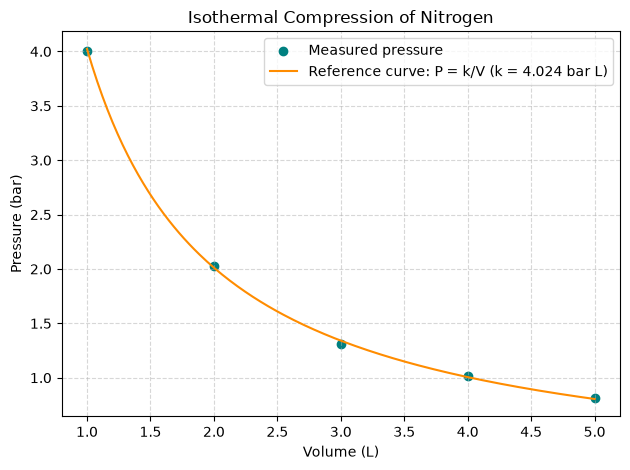

In [13]:
import numpy as np
import matplotlib.pyplot as plt

volume_L = np.array([1, 2, 3, 4, 5], dtype=float)
pressure_bar = np.array([4.00, 2.03, 1.31, 1.02, 0.81], dtype=float)

k = np.mean(pressure_bar * volume_L)
print(f"Mean k = {k:.3f} bar L")

volume_curve = np.linspace(volume_L.min(), volume_L.max(), 200)
pressure_curve = k / volume_curve

plt.scatter(volume_L, pressure_bar, color="teal", label="Measured pressure")
plt.plot(
    volume_curve,
    pressure_curve,
    color="darkorange",
    label=f"Reference curve: P = k/V (k = {k:.3f} bar L)",
)
plt.title("Isothermal Compression of Nitrogen")
plt.xlabel("Volume (L)")
plt.ylabel("Pressure (bar)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

print the mean and standard daviation of Run1 and Run2, and state which run shows more variation

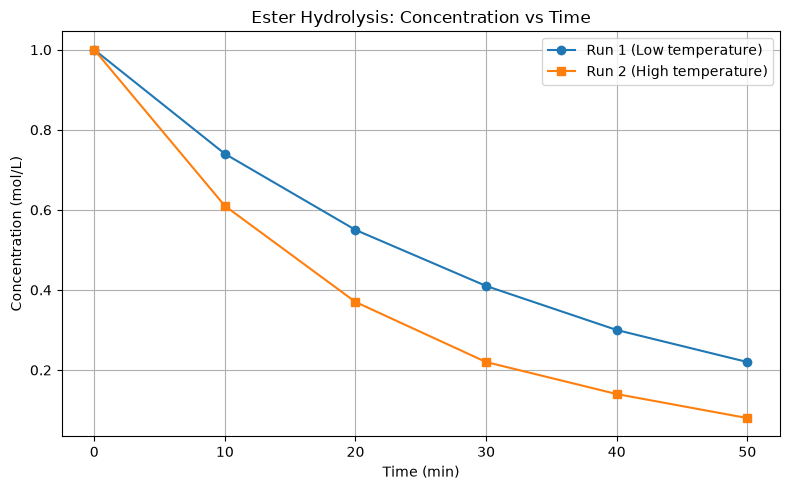

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(
    kinetics_df["time_min"],
    kinetics_df["Run1_mol_L_low_temp"],
    marker="o",
    label="Run 1 (Low temperature)",
)
plt.plot(
    kinetics_df["time_min"],
    kinetics_df["Run2_mol_L_high_temp"],
    marker="s",
    label="Run 2 (High temperature)",
)

plt.title("Ester Hydrolysis: Concentration vs Time")
plt.xlabel("Time (min)")
plt.ylabel("Concentration (mol/L)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Part A. A laboratory has n candidate additives and wants to rest r of them together in one formulation ( order does not matter). Write a recursive function factorial(n) ( remember the base case for 0!) and function combination (n,r)=n!/(r!(n-r)!) that uses it . Reject invalid input (negative values,r>n). print the number of possible formulations for n=6, r=3, and show the message for n=5, r=7



In [15]:
def factorial(n):
    if n < 0:
        raise ValueError("Factorial is not defined for negative integers.")
    if n == 0:
        return 1
    return n * factorial(n - 1)


def combination(n, r):
    if n < 0 or r < 0:
        raise ValueError("n and r must be non-negative integers.")
    if r > n:
        raise ValueError("r cannot be greater than n.")
    return factorial(n) // (factorial(r) * factorial(n - r))


n, r = 6, 3
print(f"Number of formulations for n={n}, r={r}: {combination(n, r)}")

n, r = 5, 7
try:
    print(f"Number of formulations for n={n}, r={r}: {combination(n, r)}")
except ValueError as error:
    print(f"Invalid input for n={n}, r={r}: {error}")

Number of formulations for n=6, r=3: 20
Invalid input for n=5, r=7: r cannot be greater than n.


Part B. During a reaction , samples are taken at times= Fibonacci number*2 min. Write an iterative function fib_iter(n) that retuerns a list of the first n Fibonacci numbers, and recursive function fib_rec(k) that returns the k-th Fibonacci number (F. =0.F1=1). for n=10, check that both functions agree and print a table: SampleNo.| Fibonacci tag| Sampling time (min).

In [16]:
def fib_iter(n):
    if n < 0:
        raise ValueError("n must be non-negative.")

    values = []
    previous, current = 0, 1
    for _ in range(n):
        values.append(previous)
        previous, current = current, previous + current
    return values


def fib_rec(k):
    if k < 0:
        raise ValueError("k must be non-negative.")
    if k == 0:
        return 0
    if k == 1:
        return 1
    return fib_rec(k - 1) + fib_rec(k - 2)


n = 10
fibonacci_values = fib_iter(n)
recursive_values = [fib_rec(k) for k in range(n)]

if fibonacci_values == recursive_values:
    print("fib_iter and fib_rec agree for the first 10 Fibonacci numbers.")
else:
    print("The functions do not agree.")

print(f"{'SampleNo.':<12} | {'Fibonacci tag':<16} | {'Sampling time (min)'}")
print("-" * 56)
for sample_number, (index, value) in enumerate(enumerate(fibonacci_values), start=1):
    print(f"{sample_number:<12} | F{index} = {value:<11} | {value * 2}")

fib_iter and fib_rec agree for the first 10 Fibonacci numbers.
SampleNo.    | Fibonacci tag    | Sampling time (min)
--------------------------------------------------------
1            | F0 = 0           | 0
2            | F1 = 1           | 2
3            | F2 = 1           | 2
4            | F3 = 2           | 4
5            | F4 = 3           | 6
6            | F5 = 5           | 10
7            | F6 = 8           | 16
8            | F7 = 13          | 26
9            | F8 = 21          | 42
10           | F9 = 34          | 68
